# M01-3 | QuantizationConfig 的三個開關

M01-1、M01-2 的 quantizer 都用 `get_xnnpack_quantizer(is_per_channel=True)` 建立，
底下是 `get_symmetric_quantization_config(...)` 產生一份 `QuantizationConfig`，再 `set_global` 給整個模型。
這份 config 有三個開關：

| 參數 | 意思 |
|---|---|
| `is_per_channel` | weight 每個 output channel 各一組 scale（False：整個 weight 共用一組） |
| `is_qat` | observer 換成 fake quant，forward 時真的做 quantize → dequantize，給 QAT 訓練用 |
| `is_dynamic` | activation 不在校準時決定 qparams，改成執行時依當下的輸入計算 |

這本 notebook 用同一個模型、同一份校準資料跑過各種組合，看圖和數值差在哪。

In [1]:
import copy

import torch

from common.data import calibration_batches
from common.graph_utils import observer_nodes, qdq_nodes, short, sqnr
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)

## A. 四種設定並排

`run_one()` 把一個設定從 export 跑到 convert，回傳：插了幾個 observer、型別、q/dq 數量、輸出對 fp32 的 SQNR。
模型是沒訓練過的 `TinyConvNet`，這裡只比較量化前後的輸出，不看 accuracy。

In [2]:
def run_one(model, ex, **cfg):
    quantizer, _ = get_xnnpack_quantizer(**cfg)
    prepared = prepare_pt2e(export_module(copy.deepcopy(model), ex), quantizer)
    obs_types = sorted({type(m).__name__ for _, m in observer_nodes(prepared)})
    n_obs = len(observer_nodes(prepared))
    with torch.no_grad():
        for batch in calibration_batches(n=256, batch_size=32):
            prepared(*batch)
    converted = convert_pt2e(prepared)
    with torch.no_grad():
        out_sqnr = sqnr(model(*ex), converted(*ex))
    return [n_obs, ", ".join(obs_types), len(qdq_nodes(converted)), f"{out_sqnr:.1f}"]


model = get_model("tiny").eval()
ex = example_inputs(8)
configs = {
    "per-tensor weight": dict(is_per_channel=False),
    "per-channel weight": dict(is_per_channel=True),
    "per-channel + is_qat": dict(is_per_channel=True, is_qat=True),
    "per-channel + is_dynamic": dict(is_per_channel=True, is_dynamic=True),
}
results = {name: run_one(model, ex, **cfg) for name, cfg in configs.items()}
table([[name, *r] for name, r in results.items()],
      ["設定", "#observer", "observer 型別", "#q/dq", "輸出 SQNR (dB)"])

設定,#observer,observer 型別,#q/dq,輸出 SQNR (dB)
per-tensor weight,16,"HistogramObserver, MinMaxObserver",28,20.6
per-channel weight,16,"HistogramObserver, PerChannelMinMaxObserver",28,20.6
per-channel + is_qat,16,FusedMovingAvgObsFakeQuantize,28,17.4
per-channel + is_dynamic,2,"PerChannelMinMaxObserver, PlaceholderObserver",3,50.3


三個值得追問的地方：

1. per-tensor 和 per-channel 的 SQNR 幾乎一樣。per-channel 沒用嗎？（B 段）
2. `is_dynamic` 只剩 2 個 observer，SQNR 卻高很多。（C 段）
3. `is_qat` 把 observer 換成 `FusedMovingAvgObsFakeQuantize`。它是給訓練用的，M06 才會真的拿來訓練；
   這裡只要記得「同一個 quantizer，換一個 config，插進圖裡的東西就不同」。

## B. per-tensor ≈ per-channel：誤差主要來自 activation

只量化 weight、activation 保持 fp32，看輸出差多少。
做法是直接把模型裡每個 conv／linear 的 weight 換成 quantize → dequantize 之後的值
（BN 還沒折進 conv，只是近似 PT2E 的做法）。

In [3]:
def fake_quant_weight(w, per_channel):
    """對稱 int8：scale = absmax / 127，per-channel 時每個 output channel 各算一個。"""
    dims = tuple(range(1, w.dim()))
    scale = (w.abs().amax(dim=dims, keepdim=True) if per_channel else w.abs().max()) / 127
    return (w / scale).round().clamp(-127, 127) * scale


def weight_only_sqnr(model, ex, per_channel):
    m = copy.deepcopy(model)
    with torch.no_grad():
        for mod in m.modules():
            if isinstance(mod, (torch.nn.Conv2d, torch.nn.Linear)):
                mod.weight.copy_(fake_quant_weight(mod.weight, per_channel))
        return sqnr(model(*ex), m(*ex))


rows = [[name, f"{weight_only_sqnr(model, ex, pc):.1f}", results[full][3]]
        for name, pc, full in [("per-tensor", False, "per-tensor weight"),
                               ("per-channel", True, "per-channel weight")]]
table(rows, ["weight 粒度", "只量化 weight 的 SQNR (dB)", "完整量化的 SQNR (dB)"])

weight 粒度,只量化 weight 的 SQNR (dB),完整量化的 SQNR (dB)
per-tensor,48.7,20.6
per-channel,46.1,20.6


In [4]:
for _, w_only, full in rows:
    assert float(w_only) > float(full) + 20

只量化 weight 時，兩種粒度的 SQNR 都比完整量化高出 20 dB 以上：這個模型的誤差主要來自 activation，
所以 weight 用哪種粒度在最後的 SQNR 上看不出差別。
另一個原因是這個模型剛初始化，每個 channel 的 weight 範圍差不多。

per-channel 的價值要在「channel 之間範圍差很多」時才看得出來。造一個 weight，讓第 0 個 channel 大 100 倍：

In [5]:
w = torch.randn(4, 3, 3, 3)
w[0] *= 100.0
w_pt, w_pc = fake_quant_weight(w, per_channel=False), fake_quant_weight(w, per_channel=True)

rows = [[c, f"{float(w[c].abs().max()):.2f}", f"{sqnr(w[c], w_pt[c]):.1f}", f"{sqnr(w[c], w_pc[c]):.1f}"]
        for c in range(w.shape[0])]
rows.append(["整個 tensor", "", f"{sqnr(w, w_pt):.1f}", f"{sqnr(w, w_pc):.1f}"])
table(rows, ["channel", "absmax", "per-tensor SQNR (dB)", "per-channel SQNR (dB)"])

channel,absmax,per-tensor SQNR (dB),per-channel SQNR (dB)
0,302.52,44.0,44.0
1,3.20,4.2,44.4
2,2.55,4.9,45.7
3,2.23,2.4,45.6
整個 tensor,,38.5,44.0


per-tensor 只有一個 scale，由最大的 channel 0 決定（absmax / 127）。
其他 channel 的數值都不到一格 scale 的幾倍，量化後幾乎全被壓成 0，SQNR 只剩個位數。
「整個 tensor」那一個 row的 SQNR 被 channel 0 主導，看不出這個問題；要逐 channel 看。

weight 的 per-channel 幾乎沒有代價：scale 是常數，跟著 weight 存。activation 的 per-channel 則大多數硬體不支援。

## C. `is_dynamic`：只量化了 linear

dynamic 的 SQNR 高，是因為量化的東西少。先看 annotate 的結果：

In [6]:
gm = export_module(copy.deepcopy(model), ex)
q_dyn, _ = get_xnnpack_quantizer(is_per_channel=True, is_dynamic=True)
annotated = q_dyn.annotate(copy.deepcopy(gm))
marked = [n.name for n in annotated.graph.nodes if "quantization_annotation" in n.meta]
print("有標註的 node：", marked)
assert "linear" in marked and not any(name.startswith("conv2d") for name in marked)

有標註的 node： ['fc_weight', 'fc_bias', 'linear']


只有 `linear`（和它的 weight、bias）有標註，conv 一個都沒有。原因寫在 quantizer 的原始碼裡
（torchao 0.18 的 [`torchao/testing/pt2e/_xnnpack_quantizer.py`](https://github.com/pytorch/ao/blob/main/torchao/testing/pt2e/_xnnpack_quantizer.py)）：

- `annotate()` 一看到 global config 是 dynamic，就整個改走動態的標註路徑；conv、add 這些靜態的 annotator 完全不會執行。
- 動態路徑只處理 `DYNAMIC_OPS = ["linear"]` 這個清單。

所以這裡的 dynamic **不是**「linear 用 static、conv 改成 dynamic」，而是「只有 linear 被量化，而且用動態的方式」。
跑完 convert，看圖上剩下哪些運算：

In [7]:
prepared_dyn = prepare_pt2e(gm, q_dyn)
with torch.no_grad():
    prepared_dyn(*ex)
converted_dyn = convert_pt2e(prepared_dyn)
print(" → ".join(short(n.target) for n in converted_dyn.graph.nodes if n.op == "call_function"))

dequantize_per_channel → conv2d → relu → max_pool2d → conv2d → relu → conv2d → add → relu → max_pool2d → conv2d → relu → adaptive_avg_pool2d → flatten → choose_qparams → getitem → getitem → quantize_per_tensor → dequantize_per_tensor → linear


In [8]:
convs = [n for n in converted_dyn.graph.nodes if short(n.target) == "conv2d"]
assert all(a.op != "call_function" or "quantize" not in str(a.target) for c in convs for a in c.all_input_nodes)
assert any(short(n.target) == "choose_qparams" for n in converted_dyn.graph.nodes)
print(f"{len(convs)} 個 conv2d 的輸入都沒有 dequantize：conv 用 fp32 跑")

4 個 conv2d 的輸入都沒有 dequantize：conv 用 fp32 跑


conv2d 前面沒有任何 dq，用 fp32 的 weight 直接算。量化只發生在 linear 附近：

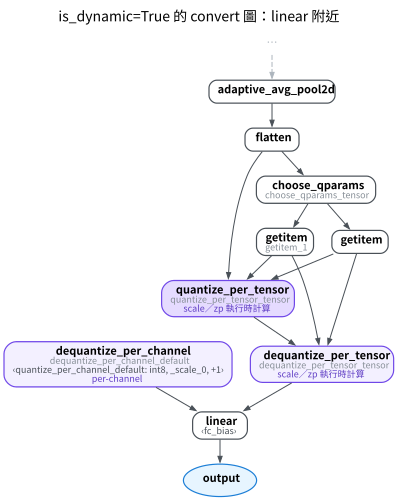

In [9]:
draw(converted_dyn, focus=["linear"], hops=4, title="is_dynamic=True 的 convert 圖：linear 附近")

同一個 linear 上，weight 和輸入用的是兩種不同的方式：

| 對象 | 量化方式 |
|---|---|
| linear 的 weight | 靜態：convert 時就存成 int8 常數（per-channel），只剩 `dequantize_per_channel` |
| linear 的輸入 activation | 動態：prepare 時插的是 `PlaceholderObserver`（不收集統計，只佔位）；convert 後變成 `choose_qparams` → `quantize_per_tensor` → `dequantize_per_tensor`，每次執行時由 `choose_qparams` 依當下的輸入算 scale／zp |
| conv 等其他 op | 不量化，沒有 q/dq |

也就是說，dynamic 指的是「activation 的 qparams 在執行時才算、不需要校準」，不是把所有 op 換成另一種量化方式；
哪些 op 支援動態量化，由 quantizer 決定。換一個 quantizer，答案就可能不同：
executorch 附的 `XNNPACKQuantizer`（M08 會用到）支援動態量化的 pattern 有 `linear`、`conv`、`conv_transpose`
（讀 executorch 1.5 原始碼；`conv_relu` 不在其中）。

回到 A 段的表：dynamic 那一個 row 只量化了 linear，其他三個 row量化了整個模型，所以 SQNR 不能直接比。

## 小結

- config 決定的是「插什麼 observer、量化哪些 op」，同一個 quantizer 換 config，圖就不同。
- 比較 SQNR 前，先確認量化了哪些 op，否則比較的對象不同。
- per-channel weight 在 channel 範圍差異大時才關鍵；要逐 channel 看誤差，整體數字會被最大的 channel 蓋過。